In [1]:
!pip install -q kagglehub

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Training on device: cuda
Epoch [1/20] - Train Loss: 0.7526 | Val Loss: 0.1848 | Val Acc: 0.9533 | Best: 0.9533
Epoch [2/20] - Train Loss: 0.1124 | Val Loss: 0.0445 | Val Acc: 0.9911 | Best: 0.9911
Epoch [3/20] - Train Loss: 0.0572 | Val Loss: 0.0407 | Val Acc: 0.9923 | Best: 0.9923
Epoch [4/20] - Train Loss: 0.0396 | Val Loss: 0.0220 | Val Acc: 0.9962 | Best: 0.9962
Epoch [5/20] - Train Loss: 0.0329 | Val Loss: 0.0166 | Val Acc: 0.9979 | Best: 0.9979
Epoch [6/20] - Train Loss: 0.0282 | Val Loss: 0.0122 | Val Acc: 0.9993 | Best: 0.9993
Epoch [7/20] - Train Loss: 0.0251 | Val Loss: 0.0140 | Val Acc: 0.9965 | Best: 0.9993
Epoch [8/20] - Train Loss: 0.0179 | Val Loss: 0.0113 | Val Acc: 0.9965 | Best: 0.9993
Epoch [9/20] - Train Loss: 0.0184 | Val Loss: 0.0310 | Val Acc: 0.9900 | Best: 0.9993
Epoch [10/20] - Train Loss: 0.0207 | Val Loss: 0.0210 | Val Acc: 0.9925 | Best: 0.9993
Epoch [11/20] - Train Loss: 0.0091 | Val

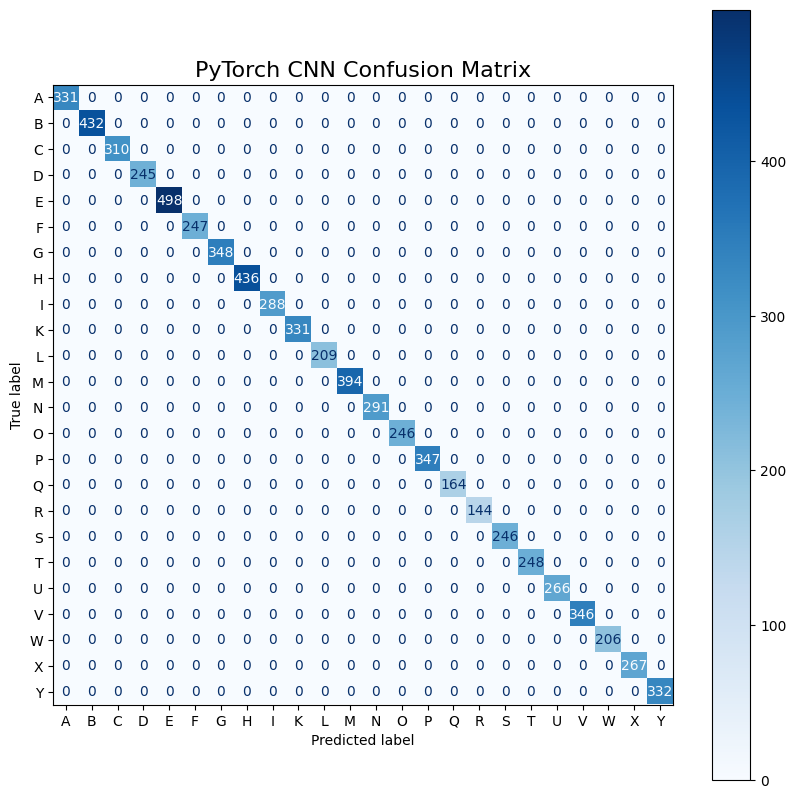

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, TensorDataset, DataLoader
from torchvision import transforms
import pandas as pd
import kagglehub
import numpy as np

config = {
    "learning_rate": 1e-3,
    "epochs": 20,
    "batch_size": 128,
    "weight_decay": 1e-4,
    "dropout": 0.3,
}

print("Downloading dataset...")
path = kagglehub.dataset_download("datamunge/sign-language-mnist")

train_df = pd.read_csv(f"{path}/sign_mnist_train.csv")
test_df = pd.read_csv(f"{path}/sign_mnist_test.csv")

y_train = train_df["label"].apply(lambda x: x - 1 if x > 9 else x).values
y_test = test_df["label"].apply(lambda x: x - 1 if x > 9 else x).values

X_train = train_df.drop(columns=["label"]).values.astype(np.float32).reshape(-1, 1, 28, 28) / 255.0
X_test = test_df.drop(columns=["label"]).values.astype(np.float32).reshape(-1, 1, 28, 28) / 255.0

X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test)
y_test_t = torch.tensor(y_test, dtype=torch.long)

train_transform = transforms.Compose(
    [
        transforms.RandomRotation(12),
        transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    ]
)


class AugmentedDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.transform is not None:
            img = self.transform(img)
        return img, self.labels[idx]


train_loader = DataLoader(
    AugmentedDataset(X_train_t, y_train_t, transform=train_transform),
    batch_size=config["batch_size"],
    shuffle=True,
)
test_loader = DataLoader(
    TensorDataset(X_test_t, y_test_t),
    batch_size=config["batch_size"],
    shuffle=False,
)


class ASL_CNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, 24),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

model = ASL_CNN(dropout=config["dropout"]).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=config["learning_rate"],
    weight_decay=config["weight_decay"],
)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

best_acc = 0.0
best_path = "asl_cnn_best.pth"

for epoch in range(config["epochs"]):
    model.train()
    running_loss = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            val_loss += criterion(outputs, labels).item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_train_loss = running_loss / len(train_loader)
    avg_val_loss = val_loss / len(test_loader)
    val_acc = correct / total
    scheduler.step(val_acc)

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), best_path)

    print(
        f"Epoch [{epoch + 1}/{config['epochs']}] - "
        f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | Best: {best_acc:.4f}"
    )

model.load_state_dict(torch.load(best_path, map_location=device))
torch.save(model.state_dict(), "asl_cnn_pytorch.pth")
print(f"Best model saved (val acc={best_acc * 100:.2f}%)")

from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    outputs = model(X_test_t.to(device))
    _, predicted_classes = torch.max(outputs, 1)

y_pred = predicted_classes.cpu().numpy()
y_true = y_test_t.cpu().numpy()

final_accuracy = accuracy_score(y_true, y_pred)
print(f"Final PyTorch Test Accuracy: {final_accuracy * 100:.2f}%\n")

letter_labels = [chr(i + 65) for i in range(26) if i not in [9, 25]]
print(classification_report(y_true, y_pred, target_names=letter_labels))

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=letter_labels, cmap="Blues", ax=ax
)
plt.title("PyTorch CNN Confusion Matrix", fontsize=16)
plt.show()


In [3]:
from google.colab import files
files.download("asl_cnn_best.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>